In [1]:
import preprocessamento as pp
import treinamento as tr
import janelas_rolantes as jr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'ITUB4.SA'
papeis_adicionais = ['BBAS3.SA', 'BBDC4.SA', 'SANB11.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=1600, data_base=base)
df_base = pp.adicionar_features_sniper(df_base)
#df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[ITUB4.SA] Cache existente cobre de 2020-01-02 a 2025-12-04.
[ITUB4.SA] Cache NÃO cobre período solicitado. Download total necessário.
[ITUB4.SA] Iniciando download de dados (lógica de atualização/complemento)...
[ITUB4.SA] Período de download yfinance: 2020-01-01 a 2026-01-12
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[ITUB4.SA] Realizando verificação de divergência entre cache antigo e dados frescos...
[ITUB4.SA] Pós-Download Total:   - Data 2020-02-26: Ref=28.23, Comp=27.41 -> DIVERGÊNCIA (2.91%)
[ITUB4.SA] Pós-Download Total:   - Data 2022-02-14: Ref=24.06, Comp=23.36 -> DIVERGÊNCIA (2.91%)
[ITUB4.SA] Pós-Download Total:   - Data 2021-12-09: Ref=20.12, Comp=19.53 -> DIVERGÊNCIA (2.91%)
ALERTA: Divergência significativa (Pós-Download Total) detectada para ITUB4.SA! Modelo pode estar obsoleto.
Login no Gmail como flaviosbert.apps@gmail.com bem-sucedido.
E-mail enviado com sucesso para:

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,mm200_close,close_norm_mm200,macd,macd_signal,macd_hist,ADX_14,DMP_14,DMN_14,BBL_20_2.0,BBM_20_2.0,BBU_20_2.0,BBB_20_2.0,BBP_20_2.0,atr_5,atr_50,obv,vwap,cmf,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov,adc_open_BBAS3,adc_high_BBAS3,adc_low_BBAS3,adc_close_BBAS3,adc_adj_close_BBAS3,adc_volume_BBAS3,adc_pct_change_BBAS3,adc_vol_BBAS3,adc_rsi_BBAS3,adc_mm200_close_BBAS3,adc_close_norm_mm200_BBAS3,adc_macd_BBAS3,adc_macd_signal_BBAS3,adc_macd_hist_BBAS3,adc_ADX_14_BBAS3,adc_DMP_14_BBAS3,adc_DMN_14_BBAS3,adc_BBL_20_2.0_BBAS3,adc_BBM_20_2.0_BBAS3,adc_BBU_20_2.0_BBAS3,adc_BBB_20_2.0_BBAS3,adc_BBP_20_2.0_BBAS3,adc_atr_5_BBAS3,adc_atr_50_BBAS3,adc_obv_BBAS3,adc_vwap_BBAS3,adc_cmf_BBAS3,adc_tr_BBAS3,adc_atr_BBAS3,adc_atr_pct_BBAS3,adc_tr_pct_BBAS3,adc_mm5_BBAS3,adc_mm20_BBAS3,adc_open_BBDC4,adc_high_BBDC4,adc_low_BBDC4,adc_close_BBDC4,adc_adj_close_BBDC4,adc_volume_BBDC4,adc_pct_change_BBDC4,adc_vol_BBDC4,adc_rsi_BBDC4,adc_mm200_close_BBDC4,adc_close_norm_mm200_BBDC4,adc_macd_BBDC4,adc_macd_signal_BBDC4,adc_macd_hist_BBDC4,adc_ADX_14_BBDC4,adc_DMP_14_BBDC4,adc_DMN_14_BBDC4,adc_BBL_20_2.0_BBDC4,adc_BBM_20_2.0_BBDC4,adc_BBU_20_2.0_BBDC4,adc_BBB_20_2.0_BBDC4,adc_BBP_20_2.0_BBDC4,adc_atr_5_BBDC4,adc_atr_50_BBDC4,adc_obv_BBDC4,adc_vwap_BBDC4,adc_cmf_BBDC4,adc_tr_BBDC4,adc_atr_BBDC4,adc_atr_pct_BBDC4,adc_tr_pct_BBDC4,adc_mm5_BBDC4,adc_mm20_BBDC4,adc_open_SANB11,adc_high_SANB11,adc_low_SANB11,adc_close_SANB11,adc_adj_close_SANB11,adc_volume_SANB11,adc_pct_change_SANB11,adc_vol_SANB11,adc_rsi_SANB11,adc_mm200_close_SANB11,adc_close_norm_mm200_SANB11,adc_macd_SANB11,adc_macd_signal_SANB11,adc_macd_hist_SANB11,adc_ADX_14_SANB11,adc_DMP_14_SANB11,adc_DMN_14_SANB11,adc_BBL_20_2.0_SANB11,adc_BBM_20_2.0_SANB11,adc_BBU_20_2.0_SANB11,adc_BBB_20_2.0_SANB11,adc_BBP_20_2.0_SANB11,adc_atr_5_SANB11,adc_atr_50_SANB11,adc_obv_SANB11,adc_vwap_SANB11,adc_cmf_SANB11,adc_tr_SANB11,adc_atr_SANB11,adc_atr_pct_SANB11,adc_tr_pct_SANB11,adc_mm5_SANB11,adc_mm20_SANB11,dist_mm20,delta_rsi,delta_rsi_3d,vol_relativo,obv_trend_5d,atr_relativo
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-12-19,38.203884,38.834949,38.048542,38.378639,38.361374,35446214,0.009191,0.018847,45.427800,35.730344,1.074119,-0.181738,0.097931,-0.279669,25.000204,26.620235,27.808589,37.125851,39.416504,41.707157,11.622812,0.273457,0.802567,0.710243,1.444872e+09,38.420710,-0.000246,0.805824,0.806473,0.021014,0.020997,38.320387,39.416504,15.0,0.09,5.5160,157928.0,159552.0,157906.0,158473.0,158473.0,5110290,21.590000,21.650000,21.410000,21.440001,21.440001,41700500,-0.006948,0.010541,44.162149,23.09220,0.928452,-0.115705,-0.053254,-0.062451,18.253351,15.570401,25.494602,21.056477,21.9025,22.748523,7.725354,0.226663,0.420633,0.535929,573010800.0,21.500000,-0.211731,0.240000,0.498153,0.023235,0.011194,21.660,21.9025,18.299999,18.700001,18.270000,18.500000,18.094618,33688200,0.009274,0.014093,47.872003,16.15150,1.145404,-0.085572,-0.014102,-0.071470,25.552928,24.574125,31.985451,17.761913,18.7935,19.825087,10.978122,0.357743,0.468355,0.401277,460936531.0,18.490000,-0.034112,0.430000,0.457326,0.024720,0.023243,18.480,18.7935,32.049999,32.639999,31.930000,32.320000,32.160824,4316200,0.008424,0.018779,48.570263,29.00295,1.114369,-0.073754,0.180191,-0.253945,24.885439,27.372783,24.134460,30.958930,33.0820,35.205069,12.835193,0.320543,0.801035,0.680619,46641063.0,32.296666,-0.119272,0.709999,0.759999,0.023515,0.021968,32.127999,33.0820,-0.026331,2.897159,2.553604,1.372587,23108668.0,1.109646
2025-12-22,38.320389,38.563107,38.145630,38.456310,38.439011,15858704,0.002024,0.018718,46.078346,35.777480,1.074875,-0.195142,0.039316,-0.234458,23.370427,25.600816,26.743662,37.100520,39.406310,41.712100,11.702645,0.293997,0.725549,0.704387,1.460731e+09,38.388349,0.047160,0.417477,0.7786

In [8]:
[c for c in df_base.columns]

['open',
 'high',
 'low',
 'close',
 'adj_close',
 'volume',
 'pct_change',
 'vol',
 'rsi',
 'mm200_close',
 'close_norm_mm200',
 'macd',
 'macd_signal',
 'macd_hist',
 'ADX_14',
 'DMP_14',
 'DMN_14',
 'BBL_20_2.0',
 'BBM_20_2.0',
 'BBU_20_2.0',
 'BBB_20_2.0',
 'BBP_20_2.0',
 'atr_5',
 'atr_50',
 'obv',
 'vwap',
 'cmf',
 'tr',
 'atr',
 'atr_pct',
 'tr_pct',
 'mm5',
 'mm20',
 'selic',
 'ipca',
 'dolar',
 'open_ibov',
 'high_ibov',
 'low_ibov',
 'close_ibov',
 'adj_close_ibov',
 'volume_ibov',
 'adc_open_BBAS3',
 'adc_high_BBAS3',
 'adc_low_BBAS3',
 'adc_close_BBAS3',
 'adc_adj_close_BBAS3',
 'adc_volume_BBAS3',
 'adc_pct_change_BBAS3',
 'adc_vol_BBAS3',
 'adc_rsi_BBAS3',
 'adc_mm200_close_BBAS3',
 'adc_close_norm_mm200_BBAS3',
 'adc_macd_BBAS3',
 'adc_macd_signal_BBAS3',
 'adc_macd_hist_BBAS3',
 'adc_ADX_14_BBAS3',
 'adc_DMP_14_BBAS3',
 'adc_DMN_14_BBAS3',
 'adc_BBL_20_2.0_BBAS3',
 'adc_BBM_20_2.0_BBAS3',
 'adc_BBU_20_2.0_BBAS3',
 'adc_BBB_20_2.0_BBAS3',
 'adc_BBP_20_2.0_BBAS3',
 'adc_a

## Verificação da volatilidade recente

In [29]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-11-19,0.617550,0.015497,0.459999,0.011543
2025-11-21,0.607725,0.015205,0.480000,0.012009
2025-11-24,0.596459,0.014979,0.449997,0.011301
2025-11-25,0.588855,0.014755,0.490002,0.012278
2025-11-26,0.618222,0.015134,1.000000,0.024480
2025-11-27,0.595492,0.014628,0.299999,0.007369
2025-11-28,0.638671,0.015338,1.200001,0.028818
2025-12-01,0.635909,0.015397,0.599998,0.014528
2025-12-02,0.656201,0.015542,0.920002,0.021791


In [30]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 1.53%
Valorização sugerida: 2.30%


## Definição do target dinamicamente com base no ATR de cada dia

In [31]:
#valorizacao = 0.05
#stop_loss = 0.03

# multiplicadores do ATR para definir alvo e stop
valorizacao_mult = 2
stop_mult = 1.3

DIAS_FUTURO = 10  # dias futuros para buscar a valorização
dias_entrada = 6


In [32]:
#df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df = pp.calcular_target_dinamico(df_base, multiplo_atr_alvo=valorizacao_mult, multiplo_atr_stop=stop_mult, dias_horizonte_alvo=DIAS_FUTURO)
df['Target'].value_counts(normalize=True)

Target
0.0    0.67722
1.0    0.32278
Name: proportion, dtype: float64

In [33]:
X, y = pp.preparar_X_y_agregado(df, dias_entrada=dias_entrada, dropna=True, tipo_drop_na='linhas', papel=papel)

c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:917: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:917: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:917: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:917: Runtim

INFO: 199 linha(s) removidas de X e y devido a NaNs.


# Sugestão do Gemini: remover épocas não-saudáveis

In [34]:
# 2. Agora criamos os filtros de regime baseados no DataFrame original
# Nota: O índice de 'X' e 'y' deve estar alinhado com 'df_base'. 
# Se 'preparar_X_y_agregado' removeu linhas (ex: dropna), precisamos alinhar os índices.

# Recriar os filtros usando o índice de X para garantir alinhamento
df_alinhado = df.loc[X.index]

# Filtro de Tendência (Preço > MM200)
filtro_tendencia = df_alinhado['close'] > df_alinhado['mm200_close']

# Filtro de Pânico (RSI > 30)
filtro_panico = df_alinhado['rsi'] > 30 

# Filtro de Volatilidade (ATR controlado)
filtro_volatilidade = df_alinhado['atr'] < (df_alinhado['atr_50'] * 2.0)

# Máscara final
mascara_regime_favoravel = filtro_tendencia & filtro_panico & filtro_volatilidade

# 3. Aplicar a filtragem APENAS no conjunto de treino/validação
# A ideia é: "Só quero aprender com exemplos bons".
# Se você forçar Target=0 nos exemplos ruins, o modelo vai aprender "quando o preço está abaixo da MM200, o alvo é 0".
# Isso é válido, mas filtrar remove o ruído completamente, focando o modelo apenas em "refinar entradas em tendência de alta".

print(f"Total de amostras disponíveis: {len(X)}")
print(f"Amostras em regime favorável: {mascara_regime_favoravel.sum()}")

# Opção A: Filtrar o dataset (Remover linhas ruins)
# Isso é seguro POIS X e y já foram calculados (não dependem mais de ordem temporal para cálculo)
X_filtrado = X[mascara_regime_favoravel].copy()
y_filtrado = y[mascara_regime_favoravel].copy()

df_filtrado = df_alinhado[mascara_regime_favoravel].copy()
# Opção B (Sua sugestão): Forçar Target 0
# y[~mascara_regime_favoravel] = 0 
# Isso mantém os dados, mas aumenta o desbalanceamento de classes (mais zeros).
# Minha recomendação: Use a Opção A (Filtrar). Modelos aprendem melhor com menos ruído.

print(f"Dataset final para treino pronto com {len(X_filtrado)} linhas.")

# Segue para divisão de treino/teste usando X_filtrado e y_filtrado...
# X_train, y_train, ... = tr.dividir_treino_validacao(X_filtrado, y_filtrado, ...)

Total de amostras disponíveis: 1273
Amostras em regime favorável: 905
Dataset final para treino pronto com 905 linhas.


In [35]:
X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X_filtrado, y_filtrado, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

# Trabalho com janelas rolantes

In [ ]:
tamanho_janela_treino = 504#252
tamanho_janela_validacao = 21

# filtro de features

Iniciando Seleção de Features com Janelas Rolantes...
Features removidas por alta correlação: 43
Total de amostras para seleção: 905
Processando janela entre 0 e 504
Processando janela entre 63 e 567
Processando janela entre 126 e 630
Processando janela entre 189 e 693
Processando janela entre 252 e 756
Processando janela entre 315 e 819
Processando janela entre 378 e 882
Importância calculada em 7 janelas.


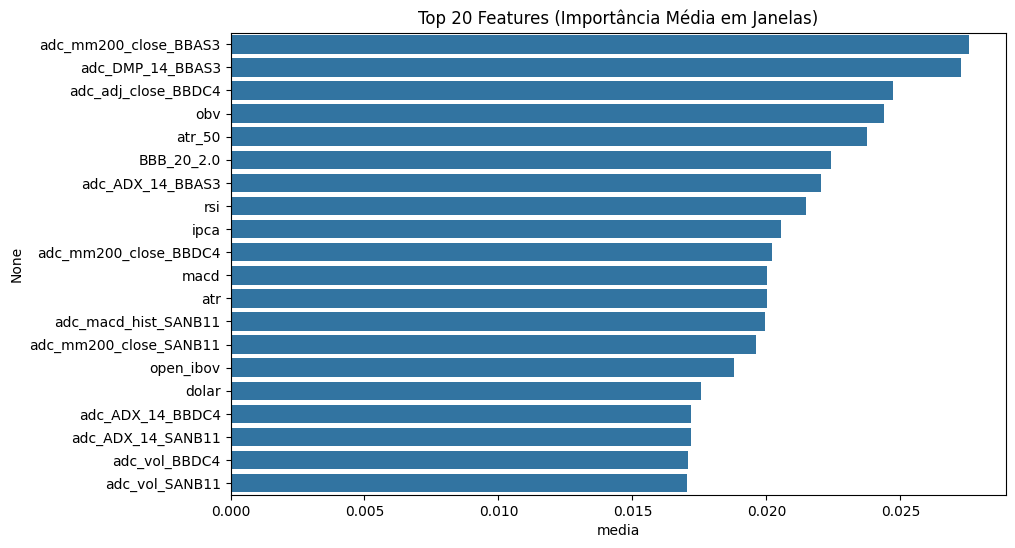

Features Finais Selecionadas (10): ['adc_mm200_close_BBAS3', 'adc_DMP_14_BBAS3', 'adc_adj_close_BBDC4', 'obv', 'atr_50', 'BBB_20_2.0', 'adc_ADX_14_BBAS3', 'rsi', 'ipca', 'adc_mm200_close_BBDC4']
Shape Final para Treino: (895, 10)


In [44]:
# --- PASSO 4: SELEÇÃO DE FEATURES (MÉDIA DE IMPORTÂNCIA EM JANELAS ROLANTES) ---

import seaborn as sns
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

num_features = 10

print("Iniciando Seleção de Features com Janelas Rolantes...")

# 1. Definir features candidatas (removendo colunas de 'metadados')
cols_numericas = df_filtrado.select_dtypes(include=[np.number]).columns
features_candidatas = [c for c in cols_numericas if c not in ['Target', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'data', 'mm5', 'mm20', 'mm200_close']]

# 2. Remover features altamente correlacionadas (> 0.95)
# Redundância atrapalha o Feature Importance
corr_matrix = df_filtrado[features_candidatas].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
features_sem_correlacao = [f for f in features_candidatas if f not in to_drop]
print(f"Features removidas por alta correlação: {len(to_drop)}")

# 3. Calcular Importância Média em Janelas Rolantes
# Em vez de treinar uma vez no DF inteiro, treinamos várias vezes em janelas de 504 dias
# e tiramos a média da importância.

tamanho_janela_selecao = tamanho_janela_treino # Mesmo tamanho do treino final
passo_selecao = 63 # Desliza a cada trimestre (~3 meses) para ser mais rápido

importancias_acumuladas = pd.DataFrame(index=features_sem_correlacao)
contador_janelas = 0

# Preparar dados completos (sem NaNs) para o loop
X_total = df_filtrado[features_sem_correlacao].fillna(0)
y_total = df_filtrado['Target'].fillna(0)

print(f"Total de amostras para seleção: {len(X_total)}")

for inicio in range(0, len(X_total) - tamanho_janela_selecao, passo_selecao):
    print(f"Processando janela entre {inicio} e {inicio + tamanho_janela_selecao}")
    fim = inicio + tamanho_janela_selecao
    
    X_janela = X_total.iloc[inicio:fim]
    y_janela = y_total.iloc[inicio:fim]
    
    # Pular se não houver classe positiva suficiente na janela
    if y_janela.sum() < 5: 
        continue
        
    # Modelo rápido para seleção
    modelo_selector = XGBClassifier(
        n_estimators=50, # Menos árvores para ser rápido
        max_depth=3, 
        learning_rate=0.1, 
        random_state=42, 
        n_jobs=-1,
        eval_metric='logloss'
    )
    modelo_selector.fit(X_janela, y_janela)
    
    # Salvar importâncias desta janela
    col_name = f'janela_{contador_janelas}'
    importancias_acumuladas[col_name] = modelo_selector.feature_importances_
    contador_janelas += 1

print(f"Importância calculada em {contador_janelas} janelas.")

# 4. Calcular Média e Estabilidade
# Calculamos a média e o desvio padrão. Features boas e estáveis são preferidas.
importancias_acumuladas['media'] = importancias_acumuladas.mean(axis=1)
importancias_acumuladas['std'] = importancias_acumuladas.std(axis=1)

# Ordenar pela média
importancias_finais = importancias_acumuladas.sort_values(by='media', ascending=False)

# Visualizar as Top 20 Médias
plt.figure(figsize=(10, 6))
sns.barplot(x=importancias_finais['media'].head(20), y=importancias_finais.index[:20])
plt.title('Top 20 Features (Importância Média em Janelas)')
plt.show()

# Selecionar as Top 15 Consistentes
top_features = importancias_finais.head(num_features).index.tolist()
print(f"Features Finais Selecionadas ({len(top_features)}): {top_features}")

# Recriar X e y finais APENAS com as features selecionadas
X_sniper = df_filtrado[top_features].copy()
y_sniper = df_filtrado['Target'].copy()

# Limpar NaNs finais
mask_not_na = ~X_sniper.isna().any(axis=1) & ~y_sniper.isna()
X_sniper = X_sniper[mask_not_na]
y_sniper = y_sniper[mask_not_na]

print(f"Shape Final para Treino: {X_sniper.shape}")

# XgBoost

In [41]:
# Imports necessários (certifique-se de instalar xgboost: pip install xgboost)
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import fbeta_score, make_scorer
from sklearn.calibration import CalibratedClassifierCV

# 1. Definir Métrica Focada em Precisão (Beta < 1 prioriza precisão)
# beta=0.3 significa que a precisão é aproximadamente 3x mais importante que o recall
scorer_sniper = make_scorer(fbeta_score, beta=0.3)

def criar_modelo_sniper(ratio_desbalanceamento=1.0):
    """
    Cria um pipeline com XGBoost configurado para precisão em dados desbalanceados.
    
    Parâmetros:
    - ratio_desbalanceamento: Razão (Negativos / Positivos). 
      Se você tem 100 dias ruins e 20 bons, o ratio é 5.
      Isso diz ao modelo: 'Preste 5x mais atenção nos acertos positivos'.
    """

    base_xgb = XGBClassifier(
            # --- Poder do Modelo ---
            n_estimators=200,       # Número de árvores
            max_depth=3,            # Árvores rasas = Menos overfitting (decora menos)
            learning_rate=0.03,     # Aprende devagar para ser consistente
            
            # --- Robustez ---
            subsample=0.7,          # Usa 80% das linhas por árvore (evita vício em dias específicos)
            colsample_bytree=0.7,   # Usa 80% das colunas por árvore
            min_child_weight=5,    # Evita árvores muito específicas
            gamma=1.5,

            # --- O Pulo do Gato para Alta Precisão ---
            scale_pos_weight=ratio_desbalanceamento, 
            
            # --- Configurações Padrão ---
            objective='binary:logistic',
            eval_metric='logloss',
            n_jobs=-1,
            random_state=42
        )
    
    # Calibrador de Probabilidade (Isotonic Regression)
    # Garante que as probabilidades sejam realistas e bem distribuídas
    calibrated = CalibratedClassifierCV(base_xgb, method='isotonic', cv=3)




    pipeline = Pipeline([
        # StandardScaler ajuda, embora árvores não exijam estritamente
        ('scaler', StandardScaler()), 
        ('modelo', calibrated)
    ])
    return pipeline

In [42]:
X_filtrado.shape

(905, 98)

In [43]:
# 1. Calcular o ratio de desbalanceamento nos dados de TREINO filtrados
# (Faça isso logo após aplicar o filtro hard e antes de chamar a otimização)
num_negativos = np.sum(y_filtrado == 0)
num_positivos = np.sum(y_filtrado == 1)
ratio = float(num_negativos) / num_positivos if num_positivos > 0 else 1.0

print(f"Ratio de Desbalanceamento calculado: {ratio:.2f}")

# 2. Criar a fábrica (lambda) já com o ratio injetado
# Isso é necessário porque sua função 'otimizar_threshold...' espera uma função sem argumentos
fabrica_modelo = lambda: criar_modelo_sniper(ratio_desbalanceamento=ratio)

# 3. Rodar a otimização (usando sua função existente)
resultados_otimizacao = jr.otimizar_threshold_com_walk_forward_rolante(
    X_super_train=X_sniper, 
    y_super_train=y_sniper,
    modelo_nao_treinado_factory=fabrica_modelo, # Passamos a nova fábrica
    tamanho_janela_treino=tamanho_janela_treino,
    tamanho_janela_validacao=tamanho_janela_validacao,
    passo_wf=21,
    recall_minimo_desejado=0.05, # Aceitamos operar pouco, desde que acerte (Sniper)
    thresholds_para_testar=np.arange(0.50, 0.95, 0.02), # Testar probabilidades altas
    metrica_otimizacao=scorer_sniper
)


threshold_final = resultados_otimizacao['threshold_ideal']
print(f"Novo Threshold Sniper: {threshold_final}")

Ratio de Desbalanceamento calculado: 2.25

--- Iniciando Otimização de Threshold com Walk-Forward Rolante ---
Janela de Treino: 504 amostras, Janela de Validação: 21, Passo: 21
  Walk-Forward Janela 1: Treinando com 504, Validando com 21...
  Walk-Forward Janela 2: Treinando com 504, Validando com 21...


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\U

  Walk-Forward Janela 3: Treinando com 504, Validando com 21...
  Walk-Forward Janela 4: Treinando com 504, Validando com 21...
  Walk-Forward Janela 5: Treinando com 504, Validando com 21...
  Walk-Forward Janela 6: Treinando com 504, Validando com 21...
  Walk-Forward Janela 7: Treinando com 504, Validando com 21...
  Walk-Forward Janela 8: Treinando com 504, Validando com 21...
  Walk-Forward Janela 9: Treinando com 504, Validando com 21...
  Walk-Forward Janela 10: Treinando com 504, Validando com 21...
  Walk-Forward Janela 11: Treinando com 504, Validando com 21...
  Walk-Forward Janela 12: Treinando com 504, Validando com 21...
  Walk-Forward Janela 13: Treinando com 504, Validando com 21...
  Walk-Forward Janela 14: Treinando com 504, Validando com 21...
  Walk-Forward Janela 15: Treinando com 504, Validando com 21...
  Walk-Forward Janela 16: Treinando com 504, Validando com 21...
  Walk-Forward Janela 17: Treinando com 504, Validando com 21...
  Walk-Forward Janela 18: Treina

## Identificação de interações

In [24]:
jr.encontrar_interacoes_robustas_com_wf(
        X_train,
        y_train,
        max_profundidade = 3, # Manter a árvore rasa para focar nas interações mais fortes
        min_amostras_folha = 20,
        tamanho_janela_treino = tamanho_janela_treino,
        passo_wf = tamanho_janela_validacao
    )


--- Buscando Interações Robustas com Walk-Forward ---
Janela de Treino: 252, Passo: 21
  WF Janela 1: Treinando com 252 amostras...
  WF Janela 2: Treinando com 252 amostras...
  WF Janela 3: Treinando com 252 amostras...
  WF Janela 4: Treinando com 252 amostras...
  WF Janela 5: Treinando com 252 amostras...
  WF Janela 6: Treinando com 252 amostras...
  WF Janela 7: Treinando com 252 amostras...
  WF Janela 8: Treinando com 252 amostras...
  WF Janela 9: Treinando com 252 amostras...
  WF Janela 10: Treinando com 252 amostras...

Análise concluída após 10 janelas de treino.


,feature_1,feature_2,frequencia
0,adc_adx_ultimo_BBAS3,obv_mean,6
12,ipca_dias_desde_mudanca,obv_mean,3
14,close_norm_ultimo,obv_mean,2
9,adc_close_norm_ultimo_vs_principal_BBAS3,obv_mean,2
10,adc_adx_ultimo_BBAS3,adc_close_norm_ultimo_vs_principal_BBAS3,2
35,adc_correl_com_principal_BBDC4,dolar_std,2
44,adc_correl_com_principal_BBDC4,correl_papel_ibov,2
1,ipca_ultimo,obv_mean,1
2,adc_adx_ultimo_BBAS3,ipca_ultimo,1
8,adc_adx_ultimo_BBAS3,close_norm_mean,1


In [25]:
# features de interação
X_train['inter_adxBBAS3_x_relBBDC4'] = X_train['adc_adx_ultimo_BBAS3'] * X_train['adc_close_norm_ultimo_vs_principal_BBDC4']
X_train['inter_relGeral_x_IPCA'] = X_train['close_norm_vs_adc_norm_mean_geral'] * X_train['ipca_ultimo']
X_train['inter_cmfTrend_x_obvMean'] = X_train['cmf_trend'] * X_train['obv_mean']
X_train['inter_relBBAS3_x_obvMean'] = X_train['adc_close_norm_ultimo_vs_principal_BBAS3'] * X_train['obv_mean']

X_validacao['inter_adxBBAS3_x_relBBDC4'] = X_validacao['adc_adx_ultimo_BBAS3'] * X_validacao['adc_close_norm_ultimo_vs_principal_BBDC4']
X_validacao['inter_relGeral_x_IPCA'] = X_validacao['close_norm_vs_adc_norm_mean_geral'] * X_validacao['ipca_ultimo']
X_validacao['inter_cmfTrend_x_obvMean'] = X_validacao['cmf_trend'] * X_validacao['obv_mean']
X_validacao['inter_relBBAS3_x_obvMean'] = X_validacao['adc_close_norm_ultimo_vs_principal_BBAS3'] * X_validacao['obv_mean']

In [26]:
lista_colunas_interacao = [c for c in X_train.columns if 'inter_' in c]
lista_colunas_interacao

['inter_adxBBAS3_x_relBBDC4',
 'inter_relGeral_x_IPCA',
 'inter_cmfTrend_x_obvMean',
 'inter_relBBAS3_x_obvMean']

In [27]:
[c for c in X.columns if 'adc' in c]

['adc_close_norm_ultimo_BBAS3',
 'adc_close_norm_ultimo_vs_principal_BBAS3',
 'adc_close_norm_trend_BBAS3',
 'adc_correl_com_principal_BBAS3',
 'adc_adx_ultimo_BBAS3',
 'adc_close_norm_ultimo_BBDC4',
 'adc_close_norm_ultimo_vs_principal_BBDC4',
 'adc_close_norm_trend_BBDC4',
 'adc_correl_com_principal_BBDC4',
 'adc_adx_ultimo_BBDC4',
 'adc_close_norm_ultimo_SANB11',
 'adc_close_norm_ultimo_vs_principal_SANB11',
 'adc_close_norm_trend_SANB11',
 'adc_correl_com_principal_SANB11',
 'adc_adx_ultimo_SANB11',
 'adc_close_norm_mean_geral_ultimo',
 'close_norm_vs_adc_norm_mean_geral']

In [28]:
lista_colunas_adc_close = [c for c in X.columns if 'adc_close_norm_ultimo_vs' in c]
lista_colunas_adc_close

['adc_close_norm_ultimo_vs_principal_BBAS3',
 'adc_close_norm_ultimo_vs_principal_BBDC4',
 'adc_close_norm_ultimo_vs_principal_SANB11']

## Seleção de features

In [29]:
from sklearn.pipeline import Pipeline


GRUPOS_CANDIDATOS = {
    'heroicas': [
        'close_norm_ultimo', 'retorno_acumulado_norm', 'atr_pct_ultimo',
        'cmf_ultimo', 'alpha_papel_vs_ibov_mean'
    ],    
    'dinamica_momentum': [
        'rsi_trend', 'macd_hist_trend'
    ],
    'dinamica_volume': [
        'volume_trend', 'correl_retorno_volume', 'obv_trend'
    ],
    'contexto_mercado': [
        'adx_ultimo', 'bbands_largura_pct_ultimo', 'ibov_trend', 'dolar_trend'
    ],
    'pares_close': lista_colunas_adc_close,
    'interacoes': lista_colunas_interacao,
    'pares': [
        'adc_close_norm_mean_geral_ultimo', 'close_norm_vs_adc_norm_mean_geral'
    ],
    'regimes': [
        'regime_tendencia', 'regime_volatilidade'
    ]
    
}

# 3. Definir o modelo template (simples e regularizado)
modelo_base_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        solver='liblinear', penalty='l2', C=0.1, random_state=42, class_weight='balanced'
    ))
])

#4. Executar a busca
#Supondo que X_train e y_train estão definidos
features_campeas_finais, df_resultados_busca = jr.encontrar_melhor_conjunto_features_incremental(
    X_train, y_train,
    GRUPOS_CANDIDATOS,
    modelo_base_pipeline,
    tamanho_janela_treino_wf=tamanho_janela_treino,
    tamanho_janela_validacao_wf=tamanho_janela_validacao    
) 

features_campeas_finais


--- Iniciando Busca Incremental pelo Melhor Conjunto de Features (Janela Rolante) ---

>>> Testando adição do grupo: 'baseline'
  Conjunto com 0 features. F1-médio (WF Rolante): 0.0000
  MELHORA! Score atual (0.0000) > Melhor anterior (-1.0000). Mantendo o grupo.

>>> Testando adição do grupo: 'heroicas'
  Conjunto com 5 features. F1-médio (WF Rolante): 0.1536
  MELHORA! Score atual (0.1536) > Melhor anterior (0.0000). Mantendo o grupo.

>>> Testando adição do grupo: 'dinamica_momentum'
  Conjunto com 7 features. F1-médio (WF Rolante): 0.2092
  MELHORA! Score atual (0.2092) > Melhor anterior (0.1536). Mantendo o grupo.

>>> Testando adição do grupo: 'dinamica_volume'
  Conjunto com 10 features. F1-médio (WF Rolante): 0.2142
  MELHORA! Score atual (0.2142) > Melhor anterior (0.2092). Mantendo o grupo.

>>> Testando adição do grupo: 'contexto_mercado'
  Conjunto com 14 features. F1-médio (WF Rolante): 0.2069
  Sem melhora. Score atual (0.2069) <= Melhor anterior (0.2142). Descartando o 

['alpha_papel_vs_ibov_mean',
 'atr_pct_ultimo',
 'close_norm_ultimo',
 'cmf_ultimo',
 'correl_retorno_volume',
 'macd_hist_trend',
 'obv_trend',
 'regime_tendencia',
 'regime_volatilidade',
 'retorno_acumulado_norm',
 'rsi_trend',
 'volume_trend']

In [30]:
X_train_subset = X_train[features_campeas_finais].copy()
X_validacao_subset = X_validacao[features_campeas_finais].copy()

## Otimização de hiperparâmetros

In [31]:
melhor_modelo_pipeline = jr.otimizar_hiperparametros_logreg_com_janela_rolante(
        X_super_treino=X_train_subset,
        y_super_treino=y_train,
        tamanho_janela_treino_wf=tamanho_janela_treino, 
        tamanho_janela_validacao_wf=tamanho_janela_validacao,  
        passo_wf=21
    )
    
print("\nModelo final (pipeline) otimizado:", melhor_modelo_pipeline)


--- Iniciando Otimização de Hiperparâmetros com Janela Rolante ---
Janela de Treino: 252, Janela de Validação: 21, Passo: 21
Fitting 9 folds for each of 25 candidates, totalling 225 fits

--- Resultados da Otimização ---
Melhor Score (F1-médio na CV rolante): 0.4159
Melhores Parâmetros Encontrados:
{'modelo__C': np.float64(0.001), 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}

Modelo final (pipeline) otimizado: Pipeline(steps=[('scaler', StandardScaler()),
                ('modelo',
                 LogisticRegression(C=np.float64(0.001),
                                    class_weight='balanced', max_iter=2000,
                                    random_state=42, solver='liblinear'))])


In [32]:
c_otimizado = melhor_modelo_pipeline['modelo'].C
penalty_otimizado = melhor_modelo_pipeline['modelo'].penalty
solver_otimizado = melhor_modelo_pipeline['modelo'].solver

## Otimização do threshold

In [33]:
recall_minimo_ex = 0.1  
class_weight = 'balanced'  

# Fábrica de modelo: uma função lambda que retorna uma nova instância do seu modelo
# Use os hiperparâmetros que você já otimizou com GridSearchCV
def criar_meu_modelo_otimizado():
    # Exemplo com RandomForest
    modelo_rl = LogisticRegression(solver=solver_otimizado, max_iter=5000,random_state=42, class_weight=class_weight, C=c_otimizado, penalty=penalty_otimizado)

    pipeline_rl = Pipeline([
        ('scaler', StandardScaler()), 
        ('modelo', modelo_rl)
    ])

    return pipeline_rl

# Executar a otimização
resultados_otimizacao = jr.otimizar_threshold_com_walk_forward_rolante(
    X_super_train=X_train_subset,
    y_super_train=y_train,
    modelo_nao_treinado_factory=criar_meu_modelo_otimizado,
    tamanho_janela_treino=tamanho_janela_treino,
    tamanho_janela_validacao=tamanho_janela_validacao,
    passo_wf=tamanho_janela_validacao,
    recall_minimo_desejado=recall_minimo_ex,
    thresholds_para_testar=np.arange(0.45, 0.56, 0.01)
)

threshold_final_para_producao = resultados_otimizacao['threshold_ideal']
print(f"\n\nO threshold final a ser usado em produção é: {threshold_final_para_producao}")


--- Iniciando Otimização de Threshold com Walk-Forward Rolante ---
Janela de Treino: 252 amostras, Janela de Validação: 21, Passo: 21
  Walk-Forward Janela 1: Treinando com 252, Validando com 21...
  Walk-Forward Janela 2: Treinando com 252, Validando com 21...
  Walk-Forward Janela 3: Treinando com 252, Validando com 21...
  Walk-Forward Janela 4: Treinando com 252, Validando com 21...
  Walk-Forward Janela 5: Treinando com 252, Validando com 21...
  Walk-Forward Janela 6: Treinando com 252, Validando com 21...
  Walk-Forward Janela 7: Treinando com 252, Validando com 21...
  Walk-Forward Janela 8: Treinando com 252, Validando com 21...
  Walk-Forward Janela 9: Treinando com 252, Validando com 21...

--- Resultados Agregados por Threshold (Walk-Forward no Super Treino) ---
    threshold  precisao_media  recall_medio  precisao_std
0        0.45           0.335         0.988         0.208
1        0.46           0.332         0.975         0.207
2        0.47           0.339         0.

### Validação Hold-out com janelas rolantes e re-treinamento


--- Iniciando Backtest Final com Walk-Forward e Retreinamento ---
Janela de Treino: 252, Passo de Retreinamento: 21
  Backtest Passo 1: Treinando com 252 amostras [2024-04-30 a 2025-05-05], Prevendo 21 amostras [2025-05-06 a 2025-06-03]...
  Backtest Passo 2: Treinando com 252 amostras [2024-05-31 a 2025-06-03], Prevendo 21 amostras [2025-06-04 a 2025-07-03]...
  Backtest Passo 3: Treinando com 252 amostras [2024-07-01 a 2025-07-03], Prevendo 21 amostras [2025-07-04 a 2025-08-01]...
  Backtest Passo 4: Treinando com 252 amostras [2024-07-30 a 2025-08-01], Prevendo 21 amostras [2025-08-04 a 2025-09-01]...
  Backtest Passo 5: Treinando com 252 amostras [2024-08-28 a 2025-09-01], Prevendo 6 amostras [2025-09-02 a 2025-09-09]...

--- Resultados Finais do Backtest no Hold-Out ---
    threshold  precisao  recall  f1_score  num_sinais
0        0.40     0.200   1.000     0.333          90
1        0.41     0.200   1.000     0.333          90
2        0.42     0.200   1.000     0.333          

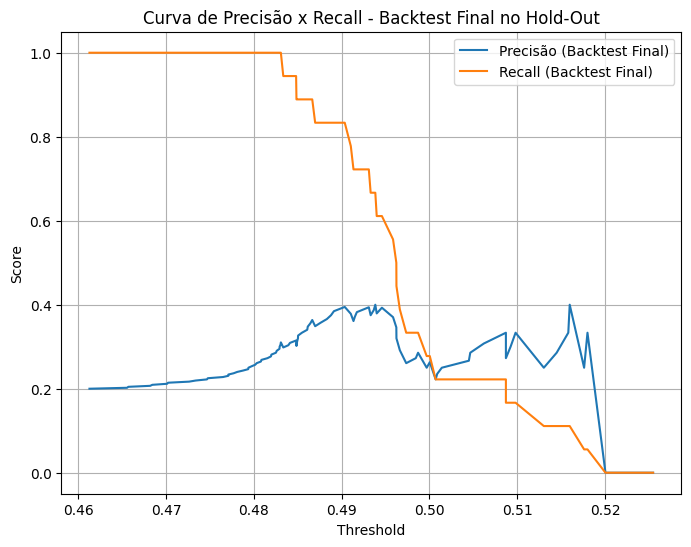

In [23]:
# Definir o modelo "campeão" (com hiperparâmetros já otimizados)
modelo_final_template = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        solver=solver_otimizado, penalty=penalty_otimizado, C=c_otimizado, random_state=42, class_weight='balanced'
    ))
])

# Executar o backtest
resultados_backtest = jr.backtest_final_walk_forward(
    modelo_template=modelo_final_template,
    X_super_treino=X_train_subset,
    y_super_treino=y_train,
    X_validacao_final=X_validacao_subset,
    y_validacao_final=y_validacao,
    tamanho_janela_treino=tamanho_janela_treino, # 1 ano
    passo_wf=tamanho_janela_validacao # Retreina a cada mês
)

# Plotar as curvas de P-R para o resultado do backtest
if resultados_backtest:
    from sklearn.metrics import precision_recall_curve
    probas_val = resultados_backtest['probas_validacao']
    y_val = resultados_backtest['y_reais_validacao']
    
    precisions, recalls, thresholds = precision_recall_curve(y_val, probas_val)
    
    plt.figure(figsize=(8, 6))
    plt.plot(thresholds, precisions[:-1], label='Precisão (Backtest Final)')
    plt.plot(thresholds, recalls[:-1], label='Recall (Backtest Final)')
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title("Curva de Precisão x Recall - Backtest Final no Hold-Out")
    plt.grid(True)
    plt.legend()
    plt.show()

In [26]:
import treinamento_lgbm as trl

recall_minimo_ex = 0.01  
class_weight = 'balanced'  

lgbm_params = {
    'objective': 'binary', # Explicitamente definir o objetivo
    'metric': 'auc', # Usar AUC como métrica de avaliação interna
    'n_estimators': 1000,
    'learning_rate': 0.05,          # Um pouco mais rápido para ver o sinal mais cedo

    # --- Parâmetros de Complexidade (Mais permissivos) ---
    'num_leaves': 31,               # Default do LGBM, um bom ponto de partida
    'max_depth': -1,                # Sem limite, deixa num_leaves controlar a complexidade
    'min_child_samples': 20,        # Default do LGBM

    # --- Parâmetros de Regularização (Leves para começar) ---
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.0,               # Desativado por padrão
    'reg_lambda': 0.0,              # Desativado por padrão
    
    # --- Outros Parâmetros ---
    'random_state': 42,
    'n_jobs': -1,
    'class_weight': 'balanced',     # Essencial
    'importance_type': 'gain',
    'verbosity': -1
}

# Fábrica de modelo: uma função lambda que retorna uma nova instância do seu modelo
# Use os hiperparâmetros que você já otimizou com GridSearchCV
def criar_meu_modelo_otimizado():
    # Exemplo com RandomForest
    modelo_calibrado, modelo_original = trl.criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo = X_train_subset, 
        y_super_treino_completo = y_train,
        fracao_eval_es = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params = lgbm_params
    )


    pipeline_rl = Pipeline([
        ('scaler', StandardScaler()), 
        ('modelo', modelo_calibrado)
    ])

    return pipeline_rl

# Executar a otimização
resultados_otimizacao = jr.otimizar_threshold_com_walk_forward_rolante(
    X_super_train=X_train_subset,
    y_super_train=y_train,
    modelo_nao_treinado_factory=criar_meu_modelo_otimizado,
    tamanho_janela_treino=tamanho_janela_treino,
    tamanho_janela_validacao=tamanho_janela_validacao,
    passo_wf=tamanho_janela_validacao,
    recall_minimo_desejado=recall_minimo_ex,
    thresholds_para_testar=np.arange(0.45, 0.56, 0.01)
)

threshold_final_para_producao = resultados_otimizacao['threshold_ideal']
print(f"\n\nO threshold final a ser usado em produção é: {threshold_final_para_producao}")


--- Iniciando Otimização de Threshold com Walk-Forward Rolante ---
Janela de Treino: 252 amostras, Janela de Validação: 21, Passo: 21
  Walk-Forward Janela 1: Treinando com 252, Validando com 21...
Dividindo Super Treino (517 amostras):
  - Treino Base LGBM: 414 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 103 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.483473
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (103 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
  Walk-Forward Janela 2: Treinando com 252, Validando com 21...
Dividindo Super Treino (517 amostras):
  - Treino Base LGBM: 414 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 103 amostras

Iniciando treinam

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Calibração concluída.
  Walk-Forward Janela 3: Treinando com 252, Validando com 21...
Dividindo Super Treino (517 amostras):
  - Treino Base LGBM: 414 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 103 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.483473
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (103 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

  Walk-Forward Janela 4: Treinando com 252, Validando com 21...
Dividindo Super Treino (517 amostras):
  - Treino Base LGBM: 414 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 103 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.483473
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (103 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
  Walk-Forward Janela 5: Treinando com 252, Validando com 21...
Dividindo Super Treino (517 amostras):
  - Treino Base LGBM: 414 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 103 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

... (8 outputs left out)

  Walk-Forward Janela 10: Treinando com 252, Validando com 21...
Dividindo Super Treino (517 amostras):
  - Treino Base LGBM: 414 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 103 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.483473
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (103 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
  Walk-Forward Janela 11: Treinando com 252, Validando com 21...
Dividindo Super Treino (517 amostras):
  - Treino Base LGBM: 414 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 103 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Calibração concluída.
  Walk-Forward Janela 12: Treinando com 252, Validando com 21...
Dividindo Super Treino (517 amostras):
  - Treino Base LGBM: 414 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 103 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.483473
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (103 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.

--- Resultados Agregados por Threshold (Walk-Forward no Super Treino) ---
    threshold  precisao_media  recall_medio  precisao_std
0        0.45             0.0           0.0           0.0
1        0.46             0.0           0.0           0.0
2        0.47             0.0           0.0           0.0
3        0.48             0.0           0.0 

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f